# 03 Evaluate: how good are the forecasts in the backtest?

In the previous notebooks, every model made thousands of forecasts in the backtest, at each month from December 2012 to August 2024, using only the months known at that time. In the present notebook, we find out **how good those forecasts were**.

Here is how we proceed. First, we measure the errors in a unit a planner understands: applications per month. Then we compare the models at our main horizon, two months ahead ($h = 2$). We do this over the whole backtest, but also without the crisis years and year by year, because one good or bad year can change the ranking. Finally, we check whether the Frontex route indicator makes the forecasts better. At the end, we use these comparisons to choose our final model (section 8), and we compare it with the random walk (section 9).

To do this, we read the backtest forecasts saved by the three estimation notebooks: the simple rules and (S)ARIMA models from `02_estimate.ipynb` (`../data/processed/backtest_forecasts.csv`), the regressions from `02b_estimate_regression.ipynb` (`../data/processed/backtest_forecasts_regression.csv`) and the regressions with the route indicator from `02c_estimate_indicator.ipynb` (`../data/processed/backtest_forecasts_indicator.csv`).

Our results are saved as four tables in `../output/tables/`: the errors of all models (`03_backtest_errors.csv`), the errors year by year at $h = 2$ (`03_backtest_errors_by_year_h2.csv`), the effect of the route indicator (`03_indicator_effect.csv`) and the comparison with the random walk (`03_random_walk.csv`). The two figures, the errors by horizon and the errors by year, go to `../output/figures/`.

Note that we work **only with the backtest** here, from 2013 to September 2024. The test period stays untouched until we have chosen our final model. If we looked at the test results first, we could be tempted to pick the model that happens to do best on those 24 months, and the test would no longer tell us how the model does on months it has never seen. So we choose first, and test afterwards.

The order in which we did things matters, so we record it here. We first chose our final model (section 8) and saved that choice on GitHub. A commit records the date and the content of the code, so anyone can check that our choice was fixed before we saw a single test result. Only then did we run the test, once (`04_test.ipynb`).

After the test, we added one more simple rule: the **random walk**, which just repeats the last known month (`02_estimate.ipynb`). It turned out to be a much harder benchmark than the two simple rules of our plan, so we show it in the tables below. But because it came after our choice, it changes neither the main comparison of our plan (section 3) nor the model we chose (section 8). Section 9 compares our chosen model with the random walk.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the forecasts and compute the errors

We first put the forecasts of the three estimation notebooks into one table, so that all models can be compared in exactly the same way.

For every forecast, we then compute two errors, because each one answers a different question.

The first is the **absolute error in applications**, $|y - \hat y|$: by how many applications the forecast missed. Its mean over all months, the mean absolute error (MAE), tells us by how many applications per month we miss on average. We use it as our main measure because it is in the unit a planner at SEM works with: "we miss by about 350 applications a month" is something one can plan around. Every miss counts in proportion to its size, so one very bad month does not dominate the result.

The second is the **squared error in logs**, $(\log y - \widehat{\log y})^2$. Taking the log turns the error into a relative one: an error of 0.10 in logs means the forecast is roughly 10% off, whether the month had 1,000 or 5,000 applications. Squaring then punishes large misses more than small ones. We report the square root of its mean (RMSE in logs) because it was the error measure of our project plan, and because it shows whether a model is good in relative terms, not just in months with many applications.

In [2]:
# The forecasts of the three estimation notebooks, stacked one below the other (pd.concat)
forecasts_sarima = pd.read_csv("../data/processed/backtest_forecasts.csv")
forecasts_regression = pd.read_csv("../data/processed/backtest_forecasts_regression.csv").drop(columns=["alpha"])
forecasts_indicator = pd.read_csv("../data/processed/backtest_forecasts_indicator.csv").drop(columns=["alpha"])
forecasts = pd.concat([forecasts_sarima, forecasts_regression, forecasts_indicator], ignore_index=True)
forecasts["month"] = pd.to_datetime(forecasts["month"])
forecasts["origin"] = pd.to_datetime(forecasts["origin"])

forecasts["abs_error"] = (forecasts["actual"] - forecasts["forecast"]).abs()
forecasts["sq_error_log"] = (forecasts["actual_log"] - forecasts["forecast_log"]) ** 2

print("Forecasts:", forecasts.shape[0], "| models:", forecasts["model"].nunique(),
      "| forecast months from", forecasts["month"].min(), "to", forecasts["month"].max())

Forecasts: 5040 | models: 12 | forecast months from 2013-01-01 00:00:00 to 2024-09-01 00:00:00


## 2. Errors of all models for all horizons

We now put all twelve models side by side, for each of the three horizons. We order them from the simplest to the most complex: first the three simple rules, then the three (S)ARIMA models (`02_estimate.ipynb`), then the three regressions on the series' own past (`02b_estimate_regression.ipynb`), and finally the same three regressions with the route indicator (`02c_estimate_indicator.ipynb`). This order lets us see at a glance how much each step of complexity adds.

All twelve models are scored on exactly the same forecast months, with the same two error measures. This matters: if one model were scored on calmer months than another, it would look better without being better. Here, any difference in the table comes from the models themselves.

In [3]:
model_order = ["Seasonal naive", "12-month average", "Random walk",
               "ARIMA(1,1,0)", "SARIMA(1,1,0)(1,0,0)12", "SARIMA(0,1,1)(0,1,1)12",
               "Linear regression", "Ridge", "Lasso",
               "Linear regression + routes", "Ridge + routes", "Lasso + routes"]
baselines = ["Seasonal naive", "12-month average"]      # the two baselines of our project plan
added_after = ["Random walk"]                               # added on 23 November, after the test run
sarima_models = ["ARIMA(1,1,0)", "SARIMA(1,1,0)(1,0,0)12", "SARIMA(0,1,1)(0,1,1)12"]
regression_models = ["Linear regression", "Ridge", "Lasso"]
indicator_models = ["Linear regression + routes", "Ridge + routes", "Lasso + routes"]

# One fixed colour per model, the same in every figure (plt.cm.tab10).
# A model "+ routes" gets the colour of the same model without the indicator (and a dashed line below).
colors = dict(zip(model_order[:9], plt.cm.tab10(np.arange(9))))
for name in regression_models:
    colors[name + " + routes"] = colors[name]

def error_table(data):
    # MAE in persons and RMSE in logs for every model and horizon
    grouped = data.groupby(["model", "h"])
    table = pd.DataFrame({
        "MAE (persons)": grouped["abs_error"].mean(),
        "RMSE (log)": np.sqrt(grouped["sq_error_log"].mean()),
        "forecasts": grouped["abs_error"].size(),
    }).reset_index()
    return table

errors = error_table(forecasts)

mae = errors.pivot(index="model", columns="h", values="MAE (persons)").loc[model_order].round(0)
mae.columns = [f"MAE h={h}" for h in mae.columns]
rmse = errors.pivot(index="model", columns="h", values="RMSE (log)").loc[model_order].round(3)
rmse.columns = [f"RMSE log h={h}" for h in rmse.columns]

overview = pd.concat([mae, rmse], axis=1)
overview.to_csv("../output/tables/03_backtest_errors.csv")
overview

,MAE h=1,MAE h=2,MAE h=3,RMSE log h=1,RMSE log h=2,RMSE log h=3
model,,,,,,
Seasonal naive,679.0,681.0,682.0,0.436,0.437,0.438
12-month average,487.0,528.0,558.0,0.317,0.342,0.362
Random walk,259.0,379.0,487.0,0.195,0.288,0.358
"ARIMA(1,1,0)",272.0,388.0,499.0,0.207,0.292,0.361
"SARIMA(1,1,0)(1,0,0)12",260.0,371.0,468.0,0.199,0.282,0.347
"SARIMA(0,1,1)(0,1,1)12",254.0,369.0,458.0,0.191,0.274,0.328
Linear regression,256.0,358.0,452.0,0.197,0.278,0.333
Ridge,248.0,358.0,447.0,0.187,0.279,0.336
Lasso,254.0,360.0,450.0,0.193,0.281,0.338


**What we see.** The two simple rules of our plan clearly have the largest errors: at every horizon, the seasonal naive misses by about 680 applications per month and the 12-month average by 487 to 558. Both react slowly to what is happening now. The seasonal naive takes the value of the same month one year earlier, and the 12-month average mixes the last twelve months together, so a recent rise or fall barely shows up in their forecasts. All six models that use the most recent months of the series are far below them.

The random walk, added after the test (section 9), shows how much of this gain comes simply from using the latest month: by repeating the last known month, it misses by 259, 379 and 487 applications at $h = 1$, 2 and 3, close to the models.

Among the six own-history models, the differences are small. At $h = 2$ they all lie between 358 and 388 applications per month: the three regressions at 358, 358 and 360, the best SARIMA at 369, and ARIMA(1,1,0) at 388.

The two error measures do not crown the same model. By MAE, Ridge is lowest at all three horizons (248, 358 and 447). By RMSE in logs, SARIMA(0,1,1)(0,1,1)12 is lowest at $h = 2$ (0.274) and $h = 3$ (0.328), and Ridge at $h = 1$ (0.187). This is possible because the two measures look at errors differently: the MAE counts misses in applications, so months with many applications weigh more, while the RMSE in logs counts relative misses and punishes large ones more. When two reasonable measures disagree, the models are close, and neither ranking should be over-interpreted.

The seasonal naive has almost the same error at every horizon. That is expected: its forecast is always the value of twelve months earlier, so it does not matter whether we forecast one, two or three months ahead.

Finally, the three regressions with the route indicator (last three rows) are a little worse than the same regressions without it: at $h = 2$, 364 to 374 applications against 358 to 360. We look at this in detail in section 7.

**What this means for us.** Using the most recent months is what makes the big difference. The choice between the six own-history models matters much less, so we cannot choose on the average error alone: in the next sections we check whether the ranking holds without the crisis years and year by year.

## 3. The main comparison: $h = 2$

With twelve models and two error measures, it would be easy to pick the comparison that makes our work look best. To avoid that, our project plan fixed **one main comparison** in advance, following the feedback on our project plan: the **best simple baseline of our plan** (the seasonal naive or the 12-month average) against the **best model**, at the main horizon $h = 2$, by MAE in applications per month.

We let the code pick both from the table above, so that nothing is chosen by hand. We also print the best model of each family, to see whether the winner stands out clearly or only by a little.

In [4]:
h2 = errors[errors["h"] == 2].set_index("model")

best_baseline = h2.loc[baselines, "MAE (persons)"].idxmin()
best_sarima = h2.loc[sarima_models, "MAE (persons)"].idxmin()
best_regression = h2.loc[regression_models, "MAE (persons)"].idxmin()
best_indicator = h2.loc[indicator_models, "MAE (persons)"].idxmin()
best_model = h2.loc[sarima_models + regression_models + indicator_models, "MAE (persons)"].idxmin()

for label, name in [("Best simple baseline", best_baseline), ("Best (S)ARIMA model", best_sarima),
                    ("Best regression model", best_regression), ("Best model with routes", best_indicator),
                    ("Best model overall", best_model)]:
    print(f"{label + ' at h=2:':28s} {name:27s} MAE {h2.loc[name, 'MAE (persons)']:5.1f} persons   "
          f"RMSE (log) {h2.loc[name, 'RMSE (log)']:.3f}")

mae_base, mae_best = h2.loc[best_baseline, "MAE (persons)"], h2.loc[best_model, "MAE (persons)"]
rmse_base, rmse_best = h2.loc[best_baseline, "RMSE (log)"], h2.loc[best_model, "RMSE (log)"]
print()
print(f"Improvement of the best model over the best baseline: {100 * (1 - mae_best / mae_base):.0f}% lower MAE, "
      f"{100 * (1 - rmse_best / rmse_base):.0f}% lower RMSE (log)")
average_actual = forecasts[forecasts["h"] == 2]["actual"].mean()
print(f"For comparison, average actual number of applications in these months: {average_actual:.0f}")

Best simple baseline at h=2: 12-month average            MAE 527.7 persons   RMSE (log) 0.342
Best (S)ARIMA model at h=2:  SARIMA(0,1,1)(0,1,1)12      MAE 369.0 persons   RMSE (log) 0.274
Best regression model at h=2: Ridge                       MAE 357.9 persons   RMSE (log) 0.279
Best model with routes at h=2: Ridge + routes              MAE 364.1 persons   RMSE (log) 0.281
Best model overall at h=2:   Ridge                       MAE 357.9 persons   RMSE (log) 0.279

Improvement of the best model over the best baseline: 32% lower MAE, 18% lower RMSE (log)
For comparison, average actual number of applications in these months: 1850


**What we see.** The best simple baseline of our plan is the 12-month average, which misses by 527.7 applications per month (RMSE in logs 0.342). The best model overall, by MAE, is Ridge, at 357.9 applications per month (RMSE in logs 0.279). That is **32% lower MAE** and 18% lower RMSE in logs than the 12-month average. To put these numbers in perspective: in these months, there were on average 1,850 applications per month.

The winner does not stand out from its neighbours, though. Ridge is only 11 applications per month better than the best SARIMA model (369.0), about 3%, and by RMSE in logs the SARIMA model is even slightly better (0.274 against 0.279). The plain linear regression has practically the same MAE as Ridge (358 in the table above). The best model with the route indicator, Ridge + routes (364.1), is also behind Ridge without routes, so adding the indicator does not change the winner.

**What this means for us.** Using the series' own past clearly beats the simple rules of our plan, by far more than the 10% our success rule asks for. (Against the random walk, added later, the gain is much smaller: section 9.) But between the regressions and SARIMA, there is no clear winner: Ridge's advantage is far below 10%, and the other error measure points the other way. So the best own-history models, at about 358 to 369 applications per month, are the level that the route indicator would have to beat to be useful (section 7), and the choice between them has to rest on more than this one average (sections 4 and 5).

## 4. Without the crisis periods

The backtest contains two exceptional periods: the 2015–16 crisis and the drop of 2020 (see the series in `01_preprocess.ipynb`). In such months every model makes very large errors, and because the MAE counts errors in applications, these few months weigh heavily in the average. A model could then look best overall simply because it did a little better during one crisis, even if it is not better in normal times, which is what a planner deals with most of the time.

So, as planned, we also compute the errors without the forecast months of these years (2015-01 to 2016-12 and 2020-01 to 2020-12). We add a third view, the recent years only (from 2022), because they are the closest to the situation SEM faces today.

These are only **evaluation periods**: we leave the crisis months out when we compute the errors, not when the models are trained. The models were fitted exactly as before, because a real planner cannot know in advance that a crisis is coming.

In [5]:
month = forecasts["month"]
crisis = ((month >= "2015-01-01") & (month <= "2016-12-01")) | ((month >= "2020-01-01") & (month <= "2020-12-01"))

periods = {
    "all backtest months": forecasts,
    "without 2015-16 and 2020": forecasts[~crisis],
    "from 2022": forecasts[month >= "2022-01-01"],
}

rows = []
for period_name, data in periods.items():
    table = error_table(data[data["h"] == 2])
    table["period"] = period_name
    rows.append(table)
by_period = pd.concat(rows)

by_period.pivot(index="model", columns="period", values="MAE (persons)").loc[model_order, list(periods)].round(0)

period,all backtest months,without 2015-16 and 2020,from 2022
model,,,
Seasonal naive,681.0,523.0,681.0
12-month average,528.0,369.0,512.0
Random walk,379.0,309.0,488.0
"ARIMA(1,1,0)",388.0,304.0,496.0
"SARIMA(1,1,0)(1,0,0)12",371.0,281.0,450.0
"SARIMA(0,1,1)(0,1,1)12",369.0,295.0,427.0
Linear regression,358.0,286.0,413.0
Ridge,358.0,282.0,415.0
Lasso,360.0,288.0,420.0


In [6]:
# Number of forecast months in each period (h = 2)
by_period[by_period["model"] == "Seasonal naive"].set_index("period")["forecasts"]

period
all backtest months         140
without 2015-16 and 2020    104
from 2022                    33
Name: forecasts, dtype: int64

**What we see.** The three periods contain 140, 104 and 33 forecast months, so the last one, from 2022, is based on few months and should be read with care.

Without 2015–16 and 2020, all errors are smaller, as expected. The best own-history models are now SARIMA(1,1,0)(1,0,0)12 (281) and Ridge (282), against 369 for the 12-month average. The gap to the simple rule shrinks from 170 to 88 applications per month: a large part of the models' advantage was earned in the crisis years. For our chosen linear regression, the gain over the 12-month average falls from 32% to 22% (286 against 369). The random walk is at 309.

From 2022, the linear regression (413) and Ridge (415) are lowest, ahead of the best SARIMA (427). The 12-month average is at 512 and the random walk at 488. So in the recent years, the gain of the linear regression over the 12-month average is about 19%.

The models with the route indicator are a little worse than their versions without it in the first two periods. From 2022, the linear regression with routes is equal to the one without (412 against 413), while Ridge and Lasso with routes are worse (436 and 431).

**What this means for us.** The own-history models still beat the simple rules in every period, so their advantage does not come only from the crises. But it is smaller in normal times, and the best own-history model changes from one period to the next: the regressions and the (S)ARIMA models trade places. Their differences are small compared with how much the errors change between periods. To see whether one of them wins consistently, we now look year by year.

## 5. Is the difference real? Year by year

An average over twelve years can hide a lot. One model might win by a large margin in one crisis year and lose slightly in all the others, and still have the lowest average. A planner would not want that model. So we now split the backtest into its **years** and compute the MAE at $h = 2$ for each year of forecast months, from 2013 to 2024 (2013 starts in February, because the first forecast at $h = 2$ is for February 2013, and 2024 ends in September, where the backtest ends).

Each year then works a bit like a fold in cross-validation: it gives one error per model. We look at two simple things. First, in how many years one model beats another: a model that is really better should win in most years, not just on average. Second, how big the gap between two models is compared with how much their errors change from year to year: a gap of a few applications means little when the errors move by hundreds between years. This is a descriptive check, not a statistical test.

*Not seen in class:* `forecasts["month"].dt.year` gives the year of each forecast month.

In [7]:
h2_all = forecasts[forecasts["h"] == 2].copy()
h2_all["year"] = h2_all["month"].dt.year

by_year = h2_all.groupby(["year", "model"])["abs_error"].mean().reset_index()
by_year = by_year.pivot(index="year", columns="model", values="abs_error")[model_order].round(0)
by_year.columns.name = None
by_year.to_csv("../output/tables/03_backtest_errors_by_year_h2.csv")
by_year

,Seasonal naive,12-month average,Random walk,"ARIMA(1,1,0)","SARIMA(1,1,0)(1,0,0)12","SARIMA(0,1,1)(0,1,1)12",Linear regression,Ridge,Lasso,Linear regression + routes,Ridge + routes,Lasso + routes
year,,,,,,,,,,,,
2013,640.0,392.0,255.0,189.0,193.0,216.0,244.0,207.0,234.0,226.0,211.0,227.0
2014,520.0,464.0,454.0,472.0,483.0,486.0,453.0,472.0,459.0,482.0,482.0,488.0
2015,1398.0,1501.0,670.0,762.0,812.0,787.0,730.0,704.0,668.0,782.0,629.0,666.0
2016,1727.0,1187.0,785.0,832.0,785.0,703.0,692.0,746.0,762.0,770.0,794.0,830.0
2017,760.0,430.0,207.0,205.0,145.0,183.0,162.0,161.0,170.0,194.0,180.0,182.0
2018,237.0,171.0,143.0,129.0,124.0,187.0,166.0,148.0,174.0,169.0,154.0,184.0
2019,112.0,72.0,120.0,111.0,95.0,136.0,149.0,135.0,145.0,148.0,137.0,139.0
2020,286.0,267.0,288.0,294.0,297.0,262.0,274.0,285.0,277.0,278.0,291.0,289.0
2021,440.0,297.0,176.0,179.0,177.0,190.0,190.0,192.0,175.0,190.0,190.0,187.0


In [8]:
# Two comparisons, year by year: (1) best model vs best baseline, (2) best regression vs best (S)ARIMA
for a, b in [(best_model, best_baseline), (best_regression, best_sarima)]:
    wins = (by_year[a] < by_year[b]).sum()
    print(f"{a} has a lower MAE than {b} in {wins} of {by_year.shape[0]} years.")
    print(f"   Spread across years (standard deviation of the yearly MAE): {b} {by_year[b].std():.0f}, {a} {by_year[a].std():.0f}")
    print(f"   Gap between the two averages: {by_year[b].mean() - by_year[a].mean():.0f}")

Ridge has a lower MAE than 12-month average in 8 of 12 years.
   Spread across years (standard deviation of the yearly MAE): 12-month average 417, Ridge 220
   Gap between the two averages: 167
Ridge has a lower MAE than SARIMA(0,1,1)(0,1,1)12 in 9 of 12 years.
   Spread across years (standard deviation of the yearly MAE): SARIMA(0,1,1)(0,1,1)12 223, Ridge 220
   Gap between the two averages: 11


The picture shows the same table in a way that is easier to read. Each row is a model, each dot is one year, and the black bar is the average over the years. A model whose dots are spread far apart has very different errors from one year to the next; dots far to the right are the bad years.

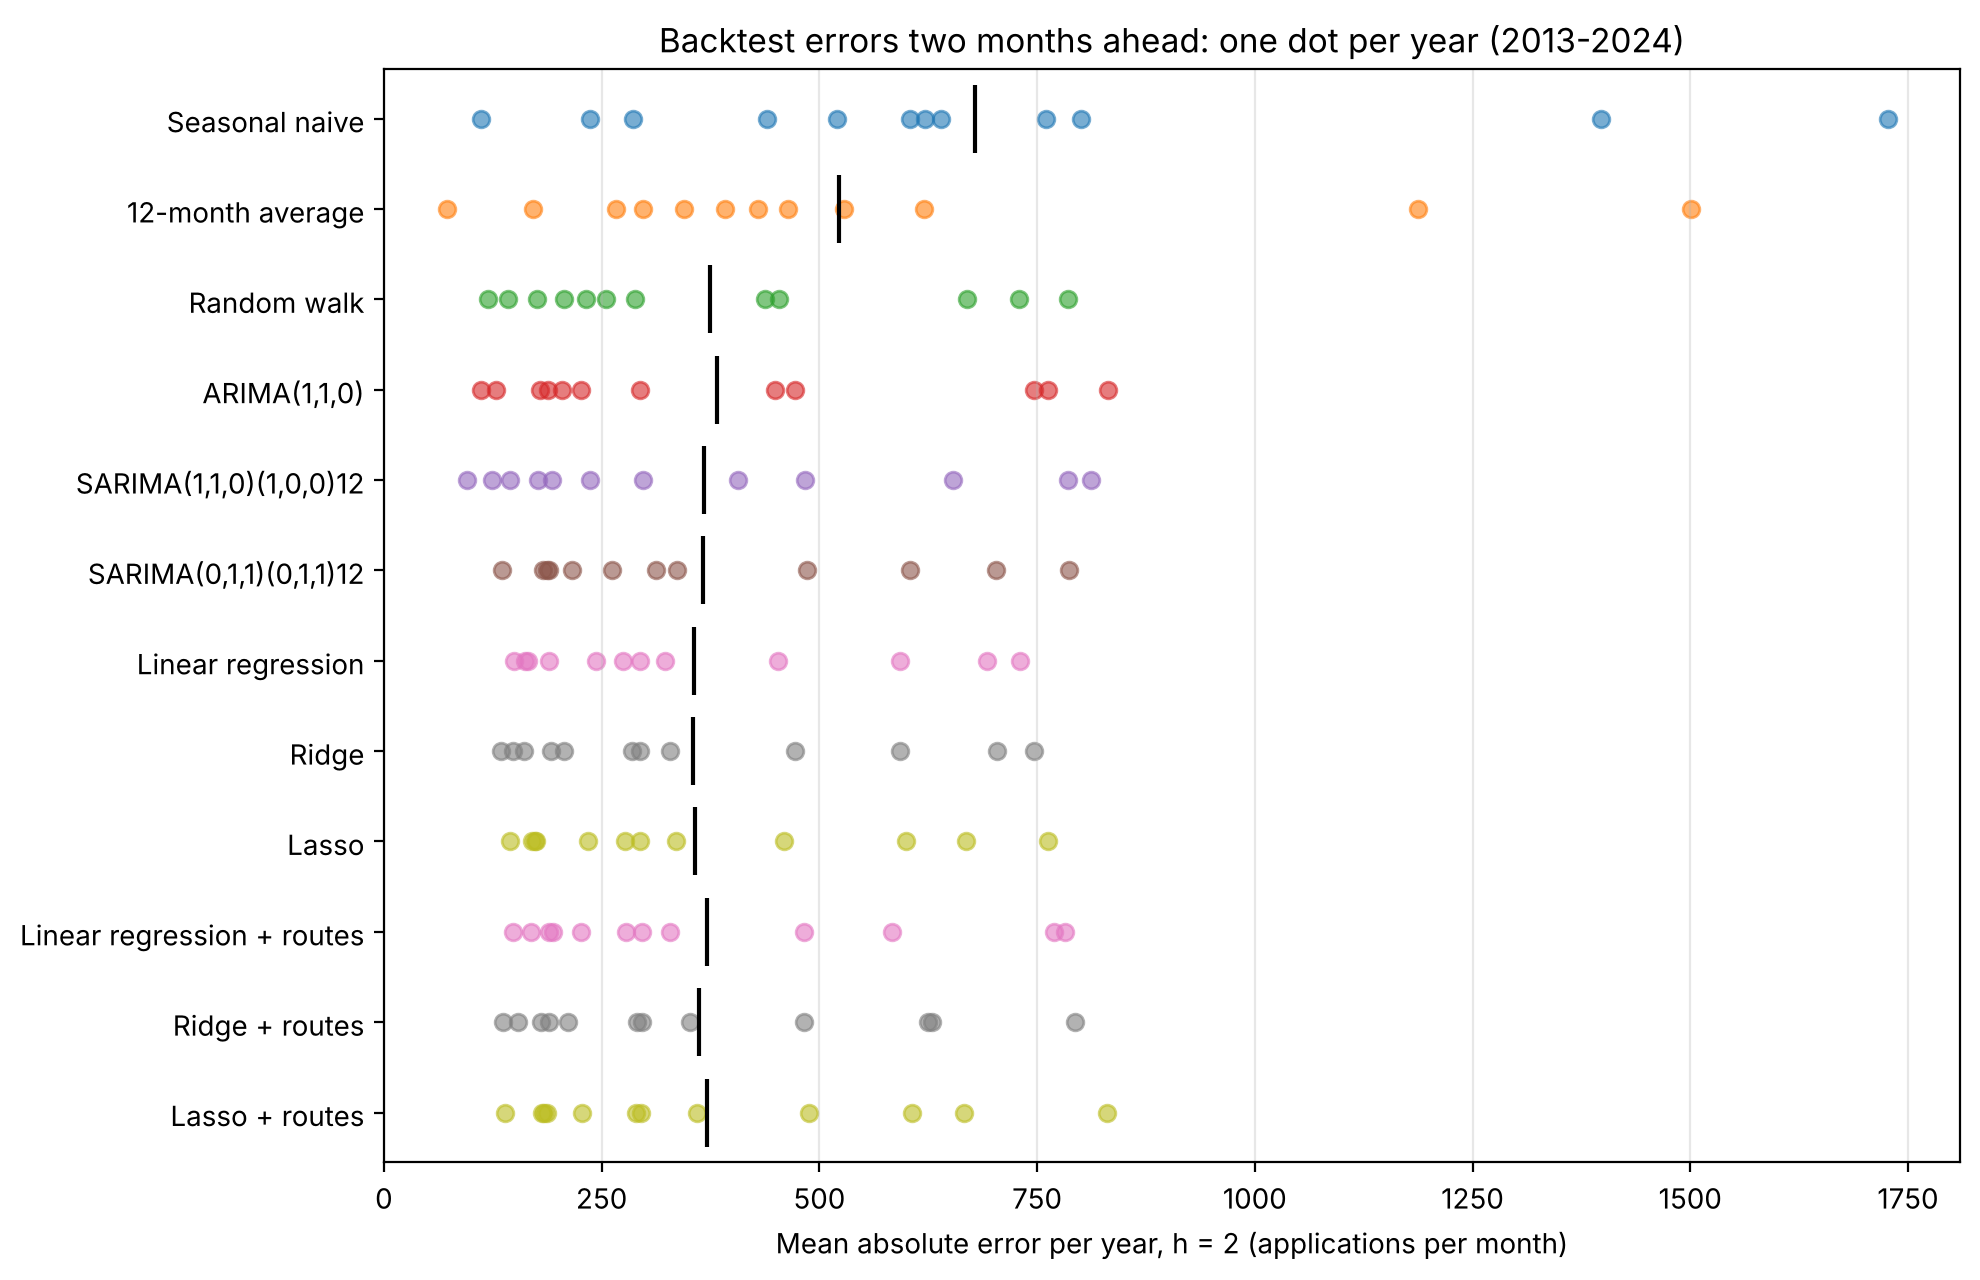

In [9]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for i, name in enumerate(model_order):
    errors_by_year = by_year[name]
    ax.scatter(errors_by_year, [i] * len(errors_by_year), alpha=0.6, color=colors[name])
    ax.scatter([errors_by_year.mean()], [i], marker="|", s=600, color="black")
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_order)
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.set_xlabel("Mean absolute error per year, h = 2 (applications per month)")
ax.set_title("Backtest errors two months ahead: one dot per year (2013-2024)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_errors_by_year_h2.png")
plt.show()

**What we see.** The code compares the best model by MAE, Ridge, with the best baseline of our plan, the 12-month average. Ridge has a lower error in 8 of 12 years. The gap between their averages (167 applications per month) is real but uneven: it is smaller than how much their errors move from year to year (standard deviation 220 for Ridge, 417 for the 12-month average). The two dots far to the right of the 12-month average, at about 1,190 and 1,500, are the years 2016 and 2015 (table above): much of the gap is earned there. Our final choice, the linear regression (section 8), does the same in 9 of 12 years.

Against the best SARIMA, Ridge also wins in 9 of 12 years, but the gap between their averages is only 11 applications per month, while their errors move by about 220 from year to year. Several of its wins are tiny (2019: 135 against 136; 2013: 207 against 216), and it loses in 2016, 2020 and 2021. Winning often by very little is not the same as being clearly better.

The random walk (third row) has its largest errors in 2015, 2016 and 2023 (670, 785 and 729), the same difficult years as the models, and is close to them in the other years.

In the picture, the six own-history models look almost the same: their averages (black bars) lie close together, between about 358 and 388. The three rows with routes look very similar to the same models without the indicator.

**What this means for us.** The advantage of the own-history models over the simple rules is consistent, since they win in most years, but much of it comes from the years with big changes. Among the six own-history models, the differences are small in practical terms, and the ranking changes from year to year. So when we choose the final model before the test period (section 8), a simpler model that is about as good as the best one is a serious candidate.

## 6. Errors over the horizon

So far we have looked mainly at $h = 2$, our main horizon. But SEM plans more than one month ahead, so we also want to know how fast the errors grow when we forecast further. The longer the horizon, the more months lie between the last number we know and the month we forecast, and the more can happen in between. We plot the MAE of each model for $h = 1$, 2 and 3. The models with the route indicator are drawn as dashed lines, so we can compare each one directly with the same model without routes.

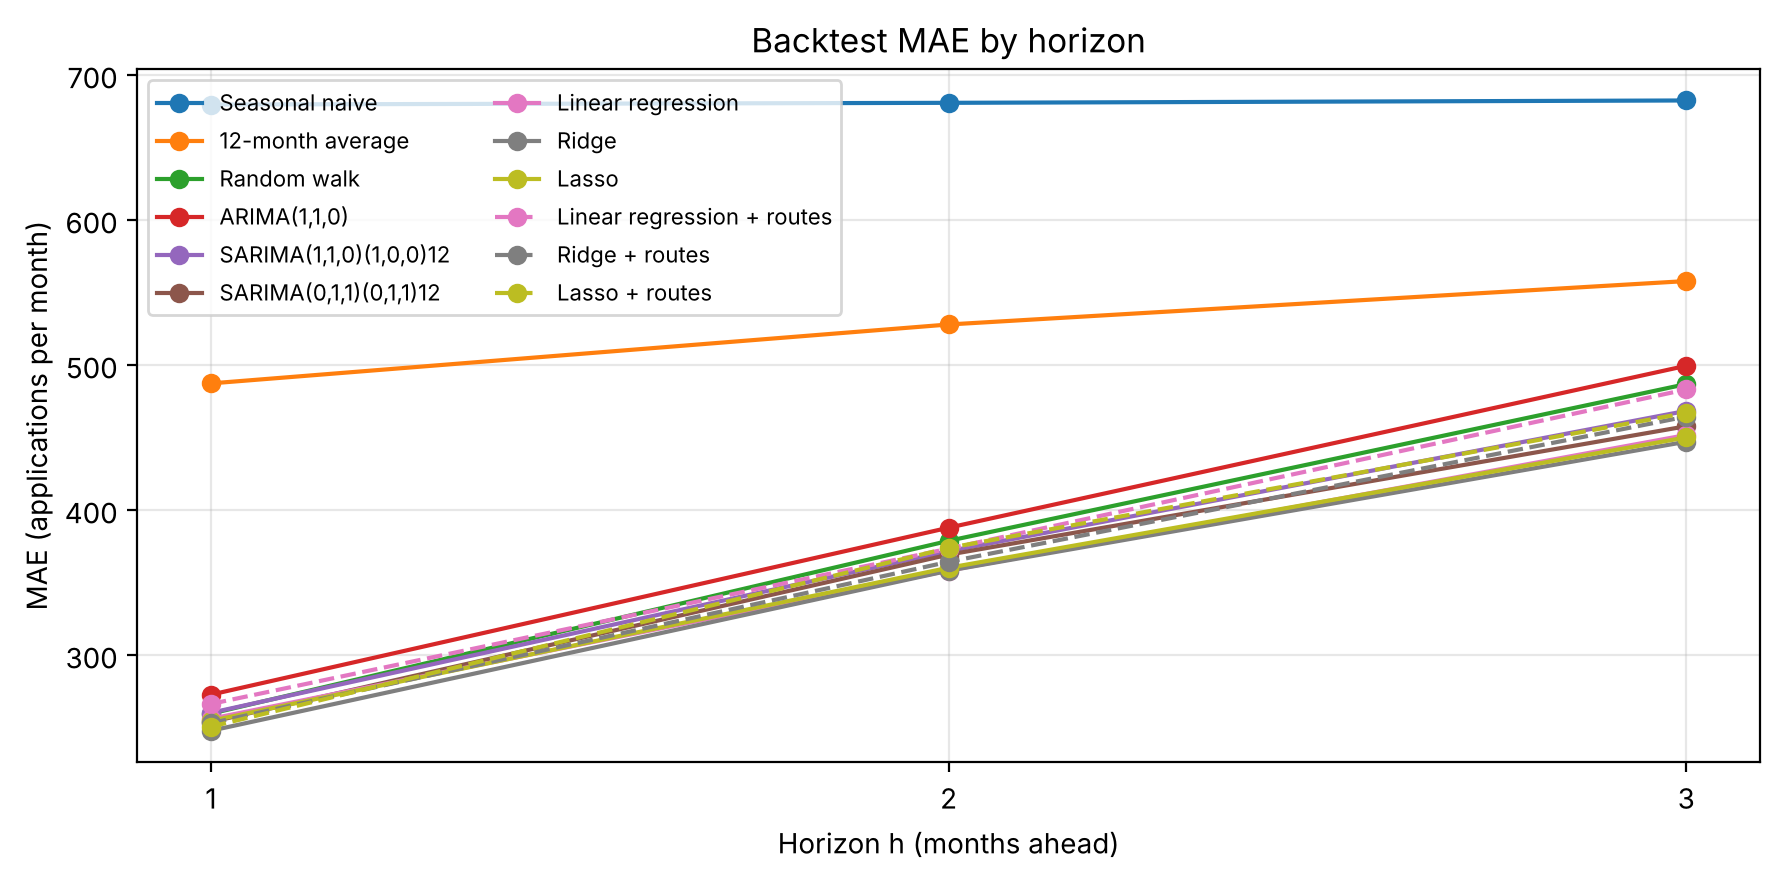

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, name in enumerate(model_order):
    one = errors[errors["model"] == name]
    style = "--" if name in indicator_models else "-"
    ax.plot(one["h"], one["MAE (persons)"], marker="o", linestyle=style, color=colors[name], label=name)
ax.set_xticks([1, 2, 3])
ax.set_xlabel("Horizon h (months ahead)")
ax.set_ylabel("MAE (applications per month)")
ax.set_title("Backtest MAE by horizon")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_mae_by_horizon.png")
plt.show()

**What we see.** For the six own-history models, the MAE grows steadily, from about 250 applications per month at $h = 1$ to about 450 to 500 at $h = 3$. This is expected: the further ahead we forecast, the less the last known months tell us about the month we want. Ridge is lowest at every horizon (248, 358 and 447), but the lines of the regressions and the SARIMA models almost overlap.

ARIMA(1,1,0) falls behind at $h = 3$ (499), close to the random walk (259, 379 and 487). Both have something in common: neither knows about the seasons. ARIMA(1,1,0) has no seasonal part, and the random walk simply repeats the last month. One month ahead, this matters little, because the next month usually looks like the last one. Three months ahead, the seasonal rise or fall in between starts to matter, and the models that know the calendar (the seasonal SARIMA models and the regressions with month dummies) pull ahead.

The 12-month average grows more slowly (from 487 to 558), because it gives the same forecast for every horizon and is already far from the current level at $h = 1$. The seasonal naive stays flat at about 680, because it always uses the value of twelve months earlier.

The dashed lines (models with the route indicator) lie slightly above the lines of the same models without it, most visibly at $h = 3$.

**What this means for us.** The further ahead we forecast, the more it pays to know the seasons. This is the main thing our regression adds to simply repeating the last month: at $h = 1$ the two are almost equal (256 against 259 for the linear regression), at $h = 3$ the regression is clearly better (452 against 487). We come back to this in section 9.

## 7. Does the route indicator help?

The idea behind the indicator was simple: people who will apply for asylum in Switzerland often cross the Mediterranean or the Balkans first, so a rise in border crossings on these routes could announce a rise in Swiss applications a few months later. If that were true, the routes would give us information that the Swiss series alone does not have yet.

To find out, our project plan adds the indicator **one block at a time**: the models of `02c` are exactly the regressions of `02b`, plus two route features, and nothing else changes. That way, any difference in the errors comes from the indicator and not from some other change. We compare each regression with its own version with routes, on the same forecast months. And we use the rule of our plan: a change counts as a clear improvement only if it lowers the MAE by at least 10%, because smaller gains could easily disappear on new data.

In [11]:
rows = []
for name in regression_models:
    for h in [1, 2, 3]:
        without = errors[(errors["model"] == name) & (errors["h"] == h)].iloc[0]
        with_routes = errors[(errors["model"] == name + " + routes") & (errors["h"] == h)].iloc[0]
        rows.append({
            "model": name, "h": h,
            "MAE without routes": without["MAE (persons)"],
            "MAE with routes": with_routes["MAE (persons)"],
            "change in MAE (%)": 100 * (with_routes["MAE (persons)"] / without["MAE (persons)"] - 1),
            "RMSE (log) without": without["RMSE (log)"],
            "RMSE (log) with": with_routes["RMSE (log)"],
        })
indicator_effect = pd.DataFrame(rows).set_index(["model", "h"])
indicator_effect.to_csv("../output/tables/03_indicator_effect.csv")
indicator_effect.round(3)

MAE without routes  MAE with routes  change in MAE (%)  \
model             h                                                           
Linear regression 1             255.864          266.060              3.985   
                  2             358.007          373.149              4.229   
                  3             451.512          482.932              6.959   
Ridge             1             247.610          252.808              2.099   
                  2             357.949          364.084              1.714   
                  3             446.888          464.199              3.874   
Lasso             1             254.440          250.398             -1.589   
                  2             359.976          373.622              3.791   
                  3             449.834          466.779              3.767   

                     RMSE (log) without  RMSE (log) with  
model             h                                       
Linear regression 1               0.197            0.203  
                  2               0.278            0.282  
                  3               0.333            0.340  
Ridge             1               0.187            0.191  
                  2               0.279            0.281  
                  3               0.336            0.340  
Lasso             1               0.193            0.190  
                  2               0.281            0.285  
                  3               0.338            0.345

**What we see.** At the main horizon $h = 2$, all three regressions get **worse** when we add the routes: the MAE goes up by 1.7% for Ridge, 3.8% for Lasso and 4.2% for the linear regression. At $h = 3$ the loss is larger, from 3.8% to 7.0%. The only gain is Lasso at $h = 1$: 250.4 instead of 254.4 applications per month (−1.6%), with a slightly lower RMSE in logs (0.190 against 0.193). The RMSE in logs tells the same story overall: with the routes it is higher in 8 of the 9 cases. No change comes anywhere near the 10% improvement our rule asks for.

**What this means for us.** The route indicator, as we can use it at the cutoff, does not improve the forecasts. The reason is timing, and we had already seen it in `01b_preprocess_indicators.ipynb`. Changes on the routes moved together with changes in Swiss applications in the same month and one month later (correlations 0.31 and 0.35), but hardly at all from two months on (0.08 or less). Frontex publishes its numbers one month later than SEM, so at the cutoff the newest route month we may use lies at least $h + 1$ months before the month we forecast. By the time a route month is published, the Swiss months it moves with are already published too. The useful part of the signal is real, but it comes too late to help.

An average over all months could again hide one lucky or unlucky period. So, as in sections 4 and 5, we check the same comparison year by year and by period, at the main horizon $h = 2$: if the routes really helped, the versions with routes should win in most years.

In [12]:
for name in regression_models:
    with_routes = name + " + routes"
    wins = (by_year[with_routes] < by_year[name]).sum()
    gap = by_year[name].mean() - by_year[with_routes].mean()
    print(f"{with_routes:27s} lower MAE than {name:18s} in {wins:2d} of {by_year.shape[0]} years | "
          f"gap of the averages {gap:6.1f} | spread across years {by_year[name].std():.0f}")
print()
by_period.pivot(index="model", columns="period", values="MAE (persons)").loc[regression_models + indicator_models, list(periods)].round(0)

Linear regression + routes  lower MAE than Linear regression  in  3 of 12 years | gap of the averages  -14.8 | spread across years 210
Ridge + routes              lower MAE than Ridge              in  2 of 12 years | gap of the averages   -6.2 | spread across years 220
Lasso + routes              lower MAE than Lasso              in  3 of 12 years | gap of the averages  -13.3 | spread across years 214



period,all backtest months,without 2015-16 and 2020,from 2022
model,,,
Linear regression,358.0,286.0,413.0
Ridge,358.0,282.0,415.0
Lasso,360.0,288.0,420.0
Linear regression + routes,373.0,291.0,412.0
Ridge + routes,364.0,292.0,436.0
Lasso + routes,374.0,297.0,431.0


In [13]:
# Year by year at h = 2: MAE of Ridge without and with the routes, and the difference
ridge_years = by_year[["Ridge", "Ridge + routes"]].copy()
ridge_years["with minus without"] = ridge_years["Ridge + routes"] - ridge_years["Ridge"]
ridge_years

,Ridge,Ridge + routes,with minus without
year,,,
2013,207.0,211.0,4.0
2014,472.0,482.0,10.0
2015,704.0,629.0,-75.0
2016,746.0,794.0,48.0
2017,161.0,180.0,19.0
2018,148.0,154.0,6.0
2019,135.0,137.0,2.0
2020,285.0,291.0,6.0
2021,192.0,190.0,-2.0


**What we see.** Year by year, the versions with routes are better in only 2 or 3 of the 12 years. On average they are 6 to 15 applications per month worse than the versions without routes; that is small compared with how much the errors move from year to year (about 210 to 220), but it is always in the same direction.

For Ridge, the one year with a clear gain is **2015**, the start of the big crisis: 629 instead of 704 applications per month (−75). But in 2016 the routes made the forecasts worse (+48), and also in 2022 and 2023 (+23 and +32); in the other years the differences are small (between −2 and +19). Without 2015–16 and 2020, all three models are worse with the routes (291 to 297 against 282 to 288). From 2022, only the linear regression with routes is about equal to the one without (412 against 413).

**What this means for us.** The loss from adding the routes is small in practical terms, but there is no sign of a gain either, except in one crisis year. One good year is not enough to choose a model: we look at all years, not at the best one. Following our plan (one block at a time, kept only if it helps), **we do not keep the route indicator in the final model**. We report this as a result in its own right: the route features we tested add nothing that is not already in the Swiss series at the time we forecast. For an indicator to help, it must still lead when it is published.

## 8. Our choice, before we look at the test period

This is the most important moment of the project. Everything we have seen so far comes from the backtest. Now we choose **one** final model and write down why, before we look at a single test month. If we waited until after the test, we could be tempted to pick whichever model happens to do best on those months, and the test would no longer be an honest check. Writing the reason down also lets anyone see later that the choice followed a rule, not the test results.

We start from the three best models at $h = 2$: Ridge and the linear regression, the best regressions by MAE, and SARIMA(0,1,1)(0,1,1)12, the best (S)ARIMA model and the best by RMSE in logs.

In [14]:
candidates = ["Ridge", "Linear regression", "SARIMA(0,1,1)(0,1,1)12"]
overview.loc[candidates]

,MAE h=1,MAE h=2,MAE h=3,RMSE log h=1,RMSE log h=2,RMSE log h=3
model,,,,,,
Ridge,248.0,358.0,447.0,0.187,0.279,0.336
Linear regression,256.0,358.0,452.0,0.197,0.278,0.333
"SARIMA(0,1,1)(0,1,1)12",254.0,369.0,458.0,0.191,0.274,0.328


**Our choice: the linear regression** of `02b`, on the series' own past, with one model per horizon.

**Why this model.** By MAE, Ridge is lowest, but the linear regression is practically equal: 358.0 against 357.9 applications per month at $h = 2$, a difference of 0.06 (section 7 table), and its RMSE in logs is even slightly lower (0.278 against 0.279). At $h = 1$ and $h = 3$, Ridge is a little better (248 against 256, and 447 against 452), but our plan fixes $h = 2$ as the main horizon, because that is the first full month a planner can still prepare for. SARIMA(0,1,1)(0,1,1)12 is about 3% worse by MAE at $h = 2$, although it is the best by RMSE in logs. All these differences are much smaller than how much the errors change from year to year (about 220, section 5), so the numbers alone cannot separate the three models.

When models are this close, we take the **simpler** one. The linear regression has no penalty, so it does not need to choose a value of `alpha` inside every training window, which removes one source of variation and one thing that could go wrong. Its coefficients can also be explained directly to a planner: how much the forecast moves with last month's change, or with the calendar month. A gap of 0.06 applications per month is not worth that extra complexity.

The route indicator is not used, because it made the forecasts worse (section 7).

**What we test, once.** We test the linear regression and, for the main comparison fixed in our project plan, the best simple baseline of the plan, the 12-month average. The test period runs from October 2024 to September 2026. The forecasts are made exactly as in the backtest: at each origin, the model is refitted on all months known at that origin, as a planner would do each month when a new number arrives. What is fixed now is the specification (the features, the model, no penalty), not the fitted numbers. We do not change this choice after seeing the test results.

## 9. Added after the test: the random walk

A forecasting model is only worth using if it beats the simplest forecast anyone could make without a model. For monthly applications, that simplest forecast is the **random walk**: "the next months will be like the last known month". It needs no data beyond last month's number, so any planner can use it.

Honestly, we should have included it in our plan from the start. Our plan compared our models with the seasonal naive and the 12-month average, and both turned out to be easy to beat because they react slowly (section 2). We added the random walk only after our choice and the test run, so it cannot change the choice anymore. But it is an important check, and leaving it out would make our results look better than they are: is our model really better than simply repeating the last month?

We compare the chosen linear regression with it in the same way as before: by horizon (as in section 6) and year by year at $h = 2$ (as in section 5).

In [15]:
rw = errors[errors["model"] == "Random walk"].set_index("h")
lr = errors[errors["model"] == "Linear regression"].set_index("h")
random_walk_check = pd.DataFrame({
    "MAE random walk": rw["MAE (persons)"],
    "MAE linear regression": lr["MAE (persons)"],
    "change in MAE (%)": 100 * (lr["MAE (persons)"] / rw["MAE (persons)"] - 1),
    "RMSE (log) random walk": rw["RMSE (log)"],
    "RMSE (log) linear regression": lr["RMSE (log)"],
})
random_walk_check.to_csv("../output/tables/03_random_walk.csv")
print(random_walk_check.round(3))
print()
wins = (by_year["Linear regression"] < by_year["Random walk"]).sum()
gap = by_year["Random walk"].mean() - by_year["Linear regression"].mean()
print(f"Linear regression lower than the random walk in {wins} of {by_year.shape[0]} years | "
      f"gap of the averages {gap:.0f} | spread across years (random walk) {by_year['Random walk'].std():.0f}")
print("Success rule (at least 10% lower MAE at h = 2):", random_walk_check.loc[2, "change in MAE (%)"] <= -10)

   MAE random walk  MAE linear regression  change in MAE (%)  \
h                                                              
1          259.397                255.864             -1.362   
2          378.536                358.007             -5.423   
3          486.619                451.512             -7.214   

   RMSE (log) random walk  RMSE (log) linear regression  
h                                                        
1                   0.195                         0.197  
2                   0.288                         0.278  
3                   0.358                         0.333  

Linear regression lower than the random walk in 7 of 12 years | gap of the averages 19 | spread across years (random walk) 237
Success rule (at least 10% lower MAE at h = 2): False


**What we see.** The chosen linear regression is better than the random walk at every horizon, but only a little: **5.4% lower MAE at $h = 2$** (358 against 379 applications per month), 1.4% at $h = 1$ (256 against 259) and 7.2% at $h = 3$ (452 against 487). At $h = 1$, the random walk even has a slightly lower RMSE in logs (0.195 against 0.197): one month ahead, repeating the last month is almost impossible to beat.

Year by year at $h = 2$, the linear regression is lower in only 7 of 12 years. Its advantage is 19 applications per month between the yearly averages (21 on all months together: 379 against 358), much smaller than how much the random walk's errors change from year to year (237). Against the random walk, our success rule of at least 10% lower MAE is **not met** in the backtest.

This changes how we should read the main comparison of section 3. The 12-month average misses by 528, the random walk by 379, our model by 358. So of the 170 applications per month our model gains over the 12-month average, 149 come simply from using the last known month, and the regression adds the last 21.

**What this means for us.** Most of what can be predicted two months ahead is already in the last known month. What our regression adds is the seasonal pattern and the partial reversal of recent jumps. That helps a little, and more the further ahead we forecast, because the seasons matter more over three months than over one (section 6). We report this honestly: our model clearly beats the two baselines of our plan, but in the backtest it is not clearly better than repeating the last month. `04_test.ipynb` also reports the random walk on the test period, for information.

## Summary

This notebook asked one question: how good were the forecasts of our twelve models in the backtest, from 2013 to September 2024, two months ahead? Here is what we found, and what it means.

**Using the latest months is what matters most.** The two simple rules of our plan react slowly to what is happening now, and they have by far the largest errors. The best of them, the 12-month average, misses by 528 applications per month. The best model by MAE, Ridge, misses by 358: **32% lower MAE** and 18% lower RMSE in logs, which meets our success rule (section 3). But the random walk, added after the test, shows where most of this gain comes from: simply repeating the last known month already brings the error down to 379. Of the 170 applications per month our chosen model gains over the 12-month average, 149 come from using the last month, and the regression adds the last 21 (section 9). Against the random walk, our 10% rule is not met.

**The own-history models are practically equal.** The regressions and the (S)ARIMA models lie within a few percent of each other. Ridge is 11 applications per month better than the best SARIMA, but SARIMA is slightly better by RMSE in logs, and the ranking changes with the period and from year to year (sections 4 and 5). What the regressions add over the random walk is the seasonal pattern and the partial reversal of recent jumps, and that helps more the further ahead we forecast (section 6).

**The advantage is real, but uneven.** The own-history models beat the simple rules in every period and in most years, but a large part of their advantage was earned in the crisis years 2015–16. Without 2015–16 and 2020, the gain of our chosen model over the 12-month average falls from 32% to 22% (section 4).

**The route indicator does not help.** Adding Frontex detections on the three routes makes the regressions 1.7% to 4.2% worse at $h = 2$, and the versions with routes win in only 2 or 3 of 12 years; the one clear gain is 2015. The routes do move with Swiss applications, but in the same month and one month later, and by the time Frontex publishes, those Swiss months are already known. So we do not keep the indicator (section 7).

**Our choice, made before the test: the linear regression** on the series' own past. It is as good as Ridge (358.0 against 357.9 applications per month at $h = 2$) and simpler: no penalty to tune, and coefficients a planner can understand (section 8). It is evaluated once on the test period in `04_test.ipynb`, together with the 12-month average of our plan and, for information, the random walk.